# Analytical verification of the HVSR solver

This notebook checks the finite-difference SH solver in `hvsr.py` (the same module the app and `hvsr_dipping_layer.ipynb` use) against closed-form results for a soft layer over rock. `hvsr_verification.ipynb` covers the numerical side (Δt convergence, sponge length, sub-cell interface). Here the focus is the physics that HVSR relies on, each compared with a formula:

| test | analytical result |
|---|---|
| 1. full spectral ratio | 1D SH transfer function $\lvert T(f)\rvert$ |
| 2. fundamental frequency | $f_0 = V_{s1}/4H$ for any $H$ and $V_{s1}$ |
| 3. higher modes | peaks at $(2n+1)\,f_0$, all the same height |
| 4. peak amplitude | $\lvert T\rvert_{\max} = C = \rho_2V_{s2}/\rho_1V_{s1}$ undamped, $1/(1/C + \pi/4Q)$ damped; depends only on the impedance contrast |
| 5. grid convergence | the error in all of the above shrinks as $\Delta x^2$ |
| 6. dipping interface | the local 1D rule $f_0(x) = V_{s1}/4H(x)$ is recovered as the dip goes to 0 |

## The analytical solution

A vertically incident SH plane wave in rock (shear modulus $\mu_2 = \rho_2V_{s2}^2$) hits a layer of thickness $H$ ($\mu_1 = \rho_1V_{s1}^2$) with a free surface at $z = 0$. In the layer the zero-traction condition $\mu_1\partial_z u = 0$ at $z=0$ leaves only a standing wave,
$$u_1(z) = A\cos k_1 z,$$
and in the rock there is an up-going incident wave and a down-going reflection,
$$u_2(z) = B\,e^{ik_2(z-H)} + D\,e^{-ik_2(z-H)},\qquad k_j = \omega / V_{sj}.$$
Continuity of displacement and traction at $z = H$,
$$A\cos k_1H = B + D,\qquad -\mu_1k_1A\sin k_1H = i\mu_2k_2(B - D),$$
gives $A$ in terms of the incident amplitude $B$. On a rock outcrop (no layer) the surface amplitude is $2B$, so the surface-to-outcrop ratio is
$$T(\omega) = \frac{A}{2B} = \frac{1}{\cos k_1H + i\,\dfrac{\mu_1k_1}{\mu_2k_2}\sin k_1H} = \frac{1}{\cos k_1H + \dfrac{i}{C}\sin k_1H},\qquad C = \frac{\rho_2V_{s2}}{\rho_1V_{s1}}.$$

**Resonances.** $\lvert T\rvert$ is largest where $\cos k_1H = 0$, i.e. $k_1H = (2n+1)\pi/2$:
$$f_n = (2n+1)\,\frac{V_{s1}}{4H},\qquad \lvert T(f_n)\rvert = C.$$
The peak height depends on $\rho$ and $V_s$ only through the impedance contrast $C$.

**Damping.** The solver's layer has a viscous term $\rho\sigma u_t$ with $\sigma = 2\pi f_0/Q$, so $k_1 = (\omega/V_{s1})\sqrt{1 - i\sigma/\omega}$. At a resonance $\operatorname{Im}(k_1H) \approx -(2n+1)\tfrac{\pi}{2}\cdot\tfrac{\sigma}{2\omega_n} = -\tfrac{\pi}{4Q}$ for every $n$, so $\cos k_1H \approx i\pi/4Q$ and
$$\lvert T(f_n)\rvert \approx \frac{1}{1/C + \pi/4Q},$$
the same for every mode (Kramer 1996, eq. 7.39 with damping ratio $\xi = 1/2Q$). Viscous damping lowers the peaks but does not move them by more than $\mathcal{O}(Q^{-2})$.

## The numerical experiment

To measure $T$ with the solver we make the model laterally infinite (periodic in $x$), put a horizontal line source in the rock, and fire one band-limited pulse (0.6-9 Hz). The same pulse is run through the layered model and through bare rock. The ratio of the two surface spectra is the FD transfer function. The bottom sponge is long (1000 m, at least one rock wavelength at $f_0$) so that it does not reflect.

In [1]:
import time, numpy as np, matplotlib.pyplot as plt
import hvsr as H
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def plane_wave(model, dx=2.5, T=30.0, depth=300.0, bottom=None, cfl=0.6):
    # Laterally infinite model + horizontal line source = vertically incident plane wave.
    # Returns frequencies and |surface spectrum over the layer| / |surface spectrum on bare rock|.
    bottom = max(1000.0, model.vs2 * 1.0) if bottom is None else bottom   # >= one rock wavelength at 1 Hz
    g = H.Grid(dx=dx, half_width=5 * dx, depth=depth, side=0, bottom=bottom, periodic_x=True, cfl=cfl)
    kw = dict(T=T, plane_wave_depth=depth - 50, rec_x=[0.0], rec_dt=0.005, pulse=True)
    s = H.simulate_noise(model, g, **kw)
    r = H.simulate_noise(model, g, homogeneous=True, **kw)
    n, dt = len(s["t"]), s["t"][1]
    f = np.fft.rfftfreq(8 * n, dt)                     # 8x zero padding for fine peak picking
    return f, np.abs(np.fft.rfft(s["u"][:, 0], 8 * n)) / np.abs(np.fft.rfft(r["u"][:, 0], 8 * n))

def peak(f, R, fc, w=0.2):
    # the maximum of R within +-w*fc of fc, refined by a parabola
    i0 = np.where((f > fc * (1 - w)) & (f < fc * (1 + w)))[0]
    i = i0[np.argmax(R[i0])]
    y0, y1, y2 = R[i - 1], R[i], R[i + 1]
    d = 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)
    return f[i] + d * (f[1] - f[0]), y1 - 0.25 * (y0 - y2) * d

def damped_peak(C, Q):
    return 1.0 / (1.0 / C + (np.pi / (4 * Q) if Q else 0.0))

m = H.Model(dip=0.0)
print(f"default model: Vs1 = {m.vs1:g} m/s, rho1 = {m.rho1:g}, Vs2 = {m.vs2:g} m/s, rho2 = {m.rho2:g}, H = {m.h0:g} m, Q = {m.q1:g}")
print(f"f0 = Vs1/4H = {m.f0_1d(0):.4f} Hz, impedance contrast C = {m.contrast:.3f}")

default model: Vs1 = 250 m/s, rho1 = 1800, Vs2 = 1000 m/s, rho2 = 2300, H = 30 m, Q = 20
f0 = Vs1/4H = 2.0833 Hz, impedance contrast C = 5.111


## 1. The whole spectral ratio
The FD ratio (red) against $\lvert T(f)\rvert$ (grey) for the default model, without and with damping. The vertical lines mark $(2n+1)V_{s1}/4H$ and the horizontal lines the predicted peak heights.

Q =    0: relative L2 misfit FD vs analytic over 0.6-8.5 Hz = 0.015


Q =   20: relative L2 misfit FD vs analytic over 0.6-8.5 Hz = 0.014


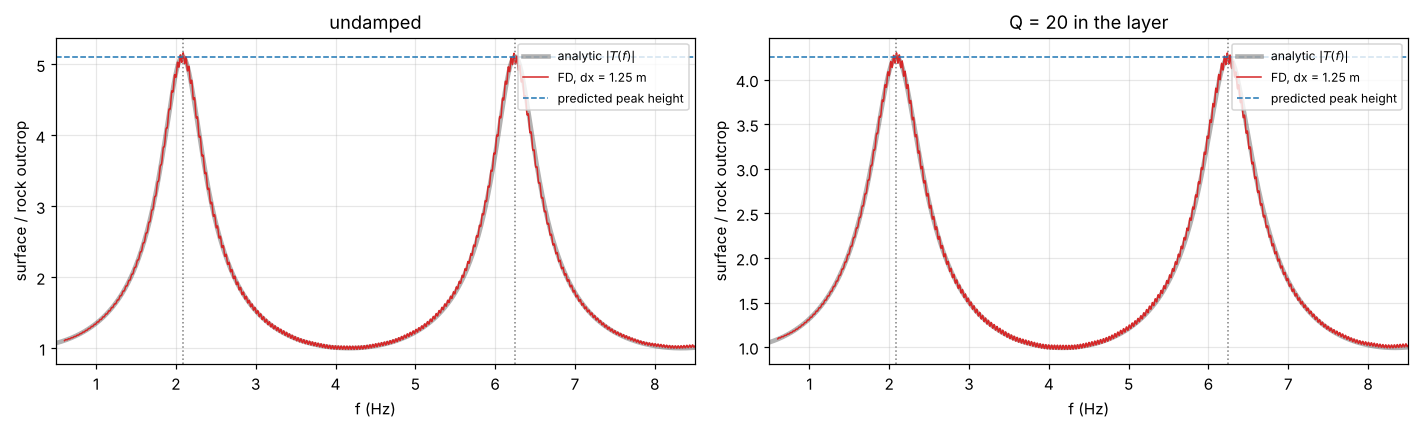

In [2]:
ff = np.linspace(0.3, 9, 4000)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for q, a in ((0.0, ax[0]), (20.0, ax[1])):
    mq = H.Model(dip=0.0, q1=q)
    f, R = plane_wave(mq, dx=1.25)
    sel = (f > 0.6) & (f < 8.5)
    a.plot(ff, mq.transfer_1d(ff), "k", lw=3, alpha=0.3, label="analytic $|T(f)|$")
    a.plot(f[sel], R[sel], "C3", lw=1, label="FD, dx = 1.25 m")
    for n in range(4):
        a.axvline((2 * n + 1) * mq.f0_1d(0), color="grey", ls=":", lw=1)
    a.axhline(damped_peak(mq.contrast, q), color="C0", ls="--", lw=1, label="predicted peak height")
    a.set(xlabel="f (Hz)", ylabel="surface / rock outcrop", xlim=(0.5, 8.5),
          title="undamped" if q == 0 else f"Q = {q:g} in the layer")
    a.legend(fontsize=8, loc="upper right")
    Ra = mq.transfer_1d(f[sel])
    print(f"Q = {q:4.0f}: relative L2 misfit FD vs analytic over 0.6-8.5 Hz = {np.sqrt(np.mean((R[sel] - Ra) ** 2) / np.mean(Ra ** 2)):.3f}")
plt.tight_layout()

## 2. Fundamental frequency $f_0 = V_{s1}/4H$
We vary the layer thickness at fixed $V_{s1} = 250$ m/s, then the layer speed at fixed $H = 30$ m, and pick the first peak of each FD ratio. Damping is on ($Q = 20$), as in the app.

 varied  value  Vs1/4H (Hz)  FD f0 (Hz)    error


      H     15       4.1667      4.1807   +0.34%


      H     20       3.1250      3.1002   -0.79%


      H     30       2.0833      2.0912   +0.38%


      H     45       1.3889      1.4062   +1.25%


      H     60       1.0417      1.0458   +0.40%


    Vs1    150       1.2500      1.2621   +0.96%


    Vs1    200       1.6667      1.6597   -0.42%


    Vs1    300       2.5000      2.5231   +0.92%


    Vs1    400       3.3333      3.3874   +1.62%


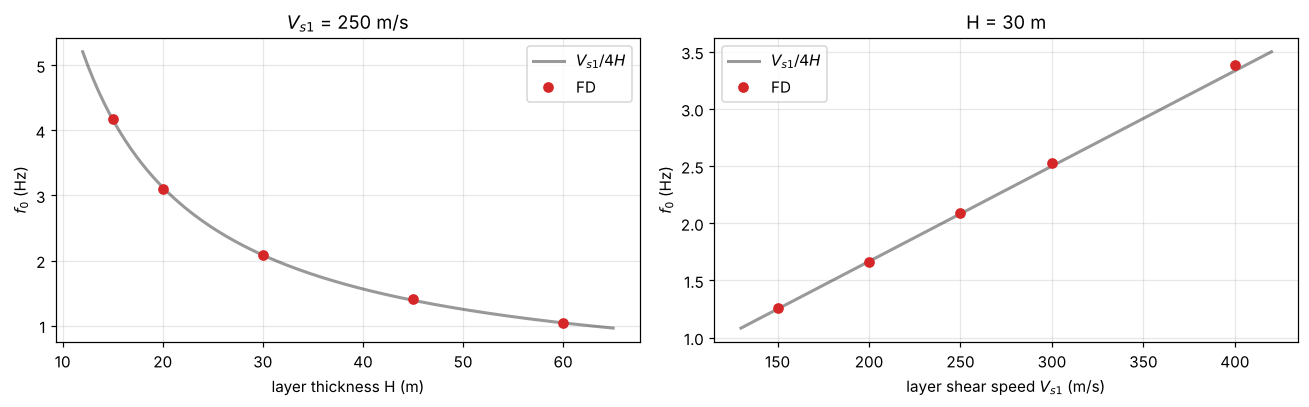

In [3]:
rows = []
for h in (15.0, 20.0, 30.0, 45.0, 60.0):
    rows.append(("H", h, H.Model(dip=0.0, h0=h)))
for v in (150.0, 200.0, 300.0, 400.0):
    rows.append(("Vs1", v, H.Model(dip=0.0, vs1=v)))
res = []
print(f"{'varied':>7} {'value':>6} {'Vs1/4H (Hz)':>12} {'FD f0 (Hz)':>11} {'error':>8}")
for name, val, mm in rows:
    f, R = plane_wave(mm)
    fp, _ = peak(f, R, mm.f0_1d(0))
    res.append((name, val, mm.f0_1d(0), fp))
    print(f"{name:>7} {val:6.0f} {mm.f0_1d(0):12.4f} {fp:11.4f} {100 * (fp / mm.f0_1d(0) - 1):+7.2f}%")
res_f0 = res

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
hh = np.linspace(12, 65, 200)
ax[0].plot(hh, 250 / (4 * hh), "k", lw=2, alpha=0.4, label="$V_{s1}/4H$")
ax[0].plot([r[1] for r in res if r[0] == "H"], [r[3] for r in res if r[0] == "H"], "o", color="C3", label="FD")
ax[0].set(xlabel="layer thickness H (m)", ylabel="$f_0$ (Hz)", title="$V_{s1}$ = 250 m/s"); ax[0].legend()
vv = np.linspace(130, 420, 200)
ax[1].plot(vv, vv / 120, "k", lw=2, alpha=0.4, label="$V_{s1}/4H$")
ax[1].plot([r[1] for r in res if r[0] == "Vs1"] + [250], [r[3] for r in res if r[0] == "Vs1"] + [res[2][3]], "o", color="C3", label="FD")
ax[1].set(xlabel="layer shear speed $V_{s1}$ (m/s)", ylabel="$f_0$ (Hz)", title="H = 30 m"); ax[1].legend()
plt.tight_layout()

## 3. Higher modes at $(2n+1)f_0$
A thicker layer ($H = 60$ m, $f_0 = 1.04$ Hz) puts four modes inside the source band. Theory says they sit at exactly 1, 3, 5, 7 times $f_0$, and with the viscous damping of the solver they all have the same height $1/(1/C + \pi/4Q)$.

In [4]:
print(f"{'Q':>4} {'n':>2} {'(2n+1)f0':>9} {'FD peak':>8} {'ratio':>7} {'FD height':>10} {'theory':>7}")
for q in (0.0, 20.0):
    mm = H.Model(dip=0.0, h0=60.0, q1=q)
    f, R = plane_wave(mm, T=40.0)
    for n in range(4):
        fn = (2 * n + 1) * mm.f0_1d(0)
        fp, ap = peak(f, R, fn, w=0.1)
        print(f"{q:4.0f} {n:2d} {fn:9.3f} {fp:8.3f} {fp / mm.f0_1d(0):7.3f} {ap:10.3f} {damped_peak(mm.contrast, q):7.3f}")

   Q  n  (2n+1)f0  FD peak   ratio  FD height  theory


   0  0     1.042    1.034   0.993      5.061   5.111
   0  1     3.125    3.127   3.002      5.168   5.111
   0  2     5.208    5.193   4.985      5.062   5.111
   0  3     7.292    7.231   6.942      5.020   5.111


  20  0     1.042    1.034   0.993      4.221   4.257
  20  1     3.125    3.127   3.002      4.314   4.257
  20  2     5.208    5.194   4.986      4.234   4.257
  20  3     7.292    7.231   6.942      4.220   4.257


## 4. Peak amplitude vs impedance contrast
We change the contrast two independent ways: by the rock **density** (rock $V_s$ stays 1000 m/s) and by the rock **velocity** (rock density stays 2300 kg/m³). Theory says only $C$ matters, so both sets should fall on the same curve: $C$ undamped and $1/(1/C + \pi/4Q)$ with $Q = 20$. The bottom sponge is lengthened with $V_{s2}$ so it stays at least one rock wavelength long at 1 Hz.

runtime 95 s
   Q    varied      C  FD peak  theory   error f_peak/f0
   0   density   2.00    2.020   2.000  +1.02%    1.0168
   0   density   3.00    3.028   3.000  +0.95%    1.0045
   0   density   5.00    5.042   5.000  +0.83%    1.0048
   0   density   8.00    8.044   8.000  +0.55%    1.0048
   0   density  12.00   12.005  12.000  +0.04%    1.0046
   0  velocity   2.00    2.020   2.000  +1.01%    1.0135
   0  velocity   3.00    3.044   3.000  +1.46%    0.9958
   0  velocity   5.00    5.054   5.000  +1.08%    1.0050
   0  velocity   8.00    8.051   8.000  +0.64%    1.0034
   0  velocity  12.00   12.073  12.000  +0.61%    1.0033
  20   density   2.00    1.874   1.854  +1.07%    1.0421
  20   density   3.00    2.709   2.684  +0.93%    1.0171
  20   density   5.00    4.218   4.179  +0.92%    1.0048
  20   density   8.00    6.141   6.088  +0.88%    1.0049
  20   density  12.00    8.222   8.156  +0.80%    1.0049
  20  velocity   2.00    1.872   1.854  +0.97%    1.0135
  20  velocity   3

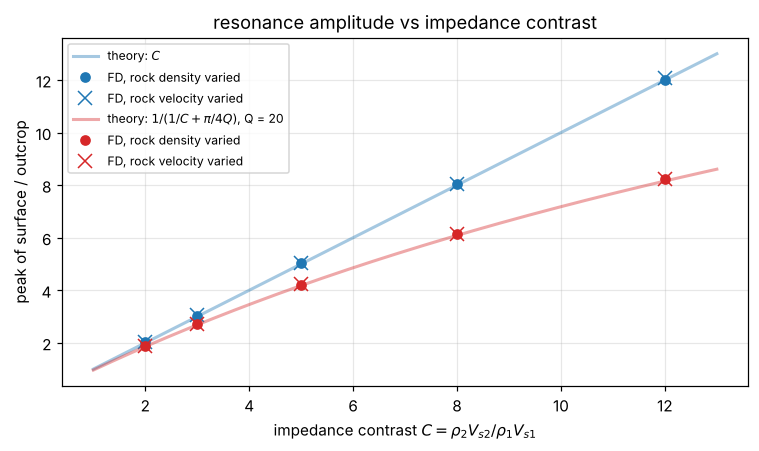

In [5]:
m0 = H.Model(dip=0.0)
Z1 = m0.rho1 * m0.vs1
Cs = np.array([2.0, 3.0, 5.0, 8.0, 12.0])
amp = {}
t0 = time.time()
for q in (0.0, 20.0):
    for how in ("density", "velocity"):
        out = []
        for C in Cs:
            if how == "density":
                mm = H.Model(dip=0.0, q1=q, rho2=C * Z1 / m0.vs2)
            else:
                mm = H.Model(dip=0.0, q1=q, vs2=C * Z1 / m0.rho2)
            f, R = plane_wave(mm, T=40.0)
            fp, ap = peak(f, R, mm.f0_1d(0))
            out.append((mm.contrast, ap, fp / mm.f0_1d(0)))
        amp[(q, how)] = np.array(out)
print(f"runtime {time.time() - t0:.0f} s")
print(f"{'Q':>4} {'varied':>9} {'C':>6} {'FD peak':>8} {'theory':>7} {'error':>7} {'f_peak/f0':>9}")
for (q, how), a in amp.items():
    for C, ap, fr in a:
        th = damped_peak(C, q)
        print(f"{q:4.0f} {how:>9} {C:6.2f} {ap:8.3f} {th:7.3f} {100 * (ap / th - 1):+6.2f}% {fr:9.4f}")

cc = np.linspace(1, 13, 200)
fig, ax = plt.subplots(figsize=(7, 4.2))
for q, col in ((0.0, "C0"), (20.0, "C3")):
    ax.plot(cc, [damped_peak(c, q) for c in cc], color=col, lw=2, alpha=0.4,
            label="theory: $C$" if q == 0 else r"theory: $1/(1/C+\pi/4Q)$, Q = 20")
    ax.plot(amp[(q, "density")][:, 0], amp[(q, "density")][:, 1], "o", color=col, label=f"FD, rock density varied{'' if q else ''}")
    ax.plot(amp[(q, "velocity")][:, 0], amp[(q, "velocity")][:, 1], "x", ms=9, color=col, label="FD, rock velocity varied")
ax.set(xlabel=r"impedance contrast $C = \rho_2V_{s2}/\rho_1V_{s1}$", ylabel="peak of surface / outcrop",
       title="resonance amplitude vs impedance contrast")
ax.legend(fontsize=8)
plt.tight_layout()

## 5. Grid convergence of the analytical comparison
For the default model (with damping) we repeat the comparison at three grid spacings and track: the relative L2 misfit of the whole ratio over 0.6-8.5 Hz, the frequency error of the fundamental ($f_0 = 2.08$ Hz) and of the second mode ($3f_0 = 6.25$ Hz), and the error in the fundamental's height. Numerical dispersion grows with frequency, so a 2nd-order scheme should show slope 2 most clearly at $3f_0$. (Time-step convergence and the sponge study are in `hvsr_verification.ipynb`.)

dx =  5.00 m ( 5.9 points per wavelength at 8.5 Hz): L2 misfit 0.1470, f0 error 0.065%, 3f0 error 3.137%, f0 peak-height error 0.44%


dx =  2.50 m (11.8 points per wavelength at 8.5 Hz): L2 misfit 0.0369, f0 error 0.084%, 3f0 error 0.822%, f0 peak-height error 1.03%


dx =  1.25 m (23.5 points per wavelength at 8.5 Hz): L2 misfit 0.0138, f0 error 0.082%, 3f0 error 0.252%, f0 peak-height error 1.15%
observed order (L2 misfit): 1.71
observed order (3f0 frequency): 1.82


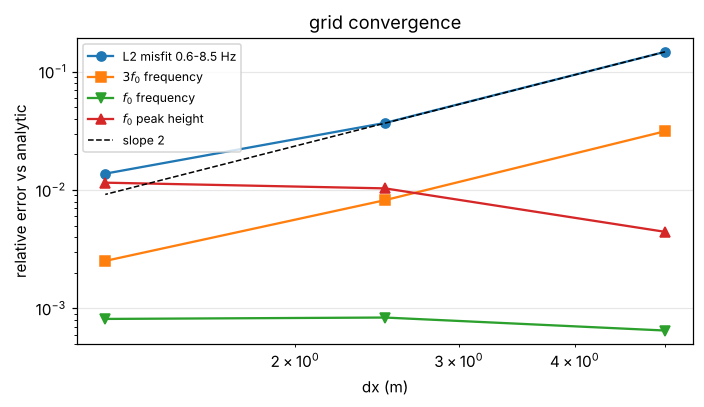

In [6]:
dxs = np.array([5.0, 2.5, 1.25])
ffine = np.linspace(0.3, 9, 40000)
fa1, Aa = peak(ffine, m.transfer_1d(ffine), m.f0_1d(0))      # analytic damped peaks
fa3, _ = peak(ffine, m.transfer_1d(ffine), 3 * m.f0_1d(0))
eL2, ef1, ef3, eA = [], [], [], []
for dx in dxs:
    f, R = plane_wave(m, dx=dx)
    sel = (f > 0.6) & (f < 8.5); Ra = m.transfer_1d(f[sel])
    eL2.append(np.sqrt(np.mean((R[sel] - Ra) ** 2) / np.mean(Ra ** 2)))
    fp1, ap = peak(f, R, m.f0_1d(0)); fp3, _ = peak(f, R, 3 * m.f0_1d(0))
    ef1.append(abs(fp1 / fa1 - 1)); ef3.append(abs(fp3 / fa3 - 1)); eA.append(abs(ap / Aa - 1))
    print(f"dx = {dx:5.2f} m ({m.vs1 / 8.5 / dx:4.1f} points per wavelength at 8.5 Hz): L2 misfit {eL2[-1]:.4f}, "
          f"f0 error {100 * ef1[-1]:.3f}%, 3f0 error {100 * ef3[-1]:.3f}%, f0 peak-height error {100 * eA[-1]:.2f}%")
for name, e in (("L2 misfit", eL2), ("3f0 frequency", ef3)):
    print(f"observed order ({name}): {np.polyfit(np.log(dxs), np.log(e), 1)[0]:.2f}")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, e, mk in (("L2 misfit 0.6-8.5 Hz", eL2, "o-"), ("$3f_0$ frequency", ef3, "s-"),
                    ("$f_0$ frequency", ef1, "v-"), ("$f_0$ peak height", eA, "^-")):
    ax.loglog(dxs, e, mk, label=name)
ax.loglog(dxs, eL2[0] * (dxs / dxs[0]) ** 2, "k--", lw=1, label="slope 2")
ax.set(xlabel="dx (m)", ylabel="relative error vs analytic", title="grid convergence"); ax.legend(fontsize=8)
plt.tight_layout()

The whole-curve misfit and the $3f_0$ frequency converge at close to 2nd order. At the fundamental, already 24-96 points per layer wavelength on these grids, the dispersion error is negligible: the $f_0$ frequency is within about 0.1% at every Δx, and the peak height has a floor of about 1% that does not depend on Δx (it comes from the finite bottom sponge and record length, see `hvsr_verification.ipynb`).

## 6. Dipping interface: when does the local 1D rule hold?
For a dipping interface there is no closed-form solution, but there is a limit: as the dip goes to zero, the 2D response must tend to the 1D one, $f_0(x) = V_{s1}/4H(x)$ at every station. Here we run the full noise simulation of the app (60 random sources in the rock, 60 s of noise, Welch spectra, Konno-Ohmachi smoothing, site / bare-rock ratio, 31 surface receivers) for dips of 0° to 15° and compare the picked $f_0(x)$ with the local 1D prediction.

Two things limit the flat-layer agreement even without dip. Body waves from point sources arrive obliquely, which shifts $f_0$ by up to $1/\cos\theta_1 - 1$ with $\sin\theta_1 \le V_{s1}/V_{s2}$ (at most 3%), and the 10 s Welch windows resolve 0.1 Hz, about 5% of a 2 Hz peak. So a misfit within about ±5% is the expected agreement; a systematic misfit beyond that is the 2D effect of the dip.

runtime 67 s
  dip  mean error  RMS error  max |error|
  0.0       -3.4%       3.9%         6.7%
  2.5       -1.3%       1.9%         4.1%
  5.0       +4.3%       5.2%         9.1%
 10.0      +14.5%      18.3%        34.0%
 15.0      +19.6%      27.1%        56.0%


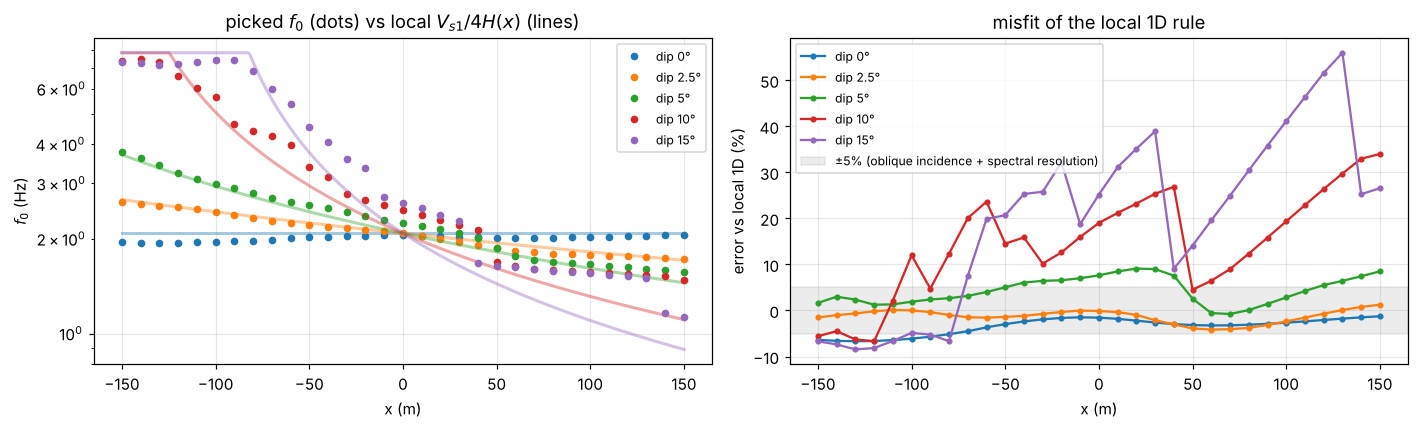

In [7]:
dips = (0.0, 2.5, 5.0, 10.0, 15.0)
prof = {}
t0 = time.time()
for d in dips:
    prof[d] = H.run_profile(H.Model(dip=d), H.default_grid(5.0), T=60.0)
print(f"runtime {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
xx = np.linspace(-150, 150, 300)
print(f"{'dip':>5} {'mean error':>11} {'RMS error':>10} {'max |error|':>12}")
for k, d in enumerate(dips):
    r, md = prof[d], H.Model(dip=d)
    err = 100 * (r["f0"] / md.f0_1d(r["rec_x"]) - 1)
    print(f"{d:5.1f} {err.mean():+10.1f}% {np.sqrt(np.mean(err ** 2)):9.1f}% {np.abs(err).max():11.1f}%")
    ax[0].plot(xx, md.f0_1d(xx), color=f"C{k}", lw=2, alpha=0.4)
    ax[0].plot(r["rec_x"], r["f0"], "o", ms=4, color=f"C{k}", label=f"dip {d:g}°")
    ax[1].plot(r["rec_x"], err, "o-", ms=3, color=f"C{k}", label=f"dip {d:g}°")
ax[0].set(xlabel="x (m)", ylabel="$f_0$ (Hz)", yscale="log", title="picked $f_0$ (dots) vs local $V_{s1}/4H(x)$ (lines)")
ax[0].legend(fontsize=8)
ax[1].axhspan(-5, 5, color="grey", alpha=0.15, label="±5% (oblique incidence + spectral resolution)")
ax[1].set(xlabel="x (m)", ylabel="error vs local 1D (%)", title="misfit of the local 1D rule"); ax[1].legend(fontsize=8)
plt.tight_layout()

## Summary
Numbers are from the saved run (Δx = 2.5 m unless stated).

* **Transfer function.** The FD surface / outcrop ratio follows the analytic 1D SH transfer function over 0.6-8.5 Hz with a 1.5% L2 misfit (Δx = 1.25 m), with and without damping.
* **$f_0 = V_{s1}/4H$.** For thicknesses from 15 to 60 m and layer speeds from 150 to 400 m/s, the FD fundamental matches $V_{s1}/4H$ within 1.6%.
* **Higher modes.** The FD peaks sit at 0.99, 3.00, 4.99 and 6.94 × $f_0$, and they have the predicted equal heights (within 2%) both undamped and with Q = 20.
* **Amplitude.** The peak height follows $C$ (undamped) and $1/(1/C + \pi/4Q)$ (damped) within 1.5% for contrasts from 2 to 12, whether the contrast comes from density or velocity: only the impedance matters.
* **Convergence.** The misfit to the analytic solution converges at close to 2nd order in Δx.
* **Dip.** At 0° and 2.5° the noise-based $f_0$ matches the local 1D rule with an RMS misfit of 2-4%, nearly all stations within the expected ±5% (worst 6.7%). The misfit grows with dip: 9% at worst at 5°, 34% at 10° and 56% at 15°. Beyond a few degrees the local 1D rule stops holding, which is the 2D effect studied in `hvsr_dipping_layer.ipynb`.

**Reference:** Kramer, S. L. (1996). *Geotechnical Earthquake Engineering*, ch. 7 (1D SH transfer function of a layer over an elastic half-space).